# Анализ лояльности пользователей Яндекс Афиши

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

**Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные. Используйте следующие параметры для подключения к базе данных `data-analyst-afisha`:

- **Хост** — `rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net`
- **База данных** — `data-analyst-afisha`
- **Порт** — `6432`
- **Аутентификация** — `Database Native`
- **Пользователь** — `praktikum_student`
- **Пароль** — `Sdf4$2;d-d30pp`

Для выгрузки используйте запрос из предыдущего урока и библиотеку SQLAlchemy.

Выгрузка из базы данных SQL должна позволить собрать следующие данные:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

---


In [1]:
import os
from getpass import getpass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import norm
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def pct(value):
    return f'{value:.1%}'

def summary(message):
    display(Markdown(message))

database_url = URL.create(
    'postgresql+psycopg2',
    username='praktikum_student',
    password=os.getenv('AFISHA_DB_PASSWORD') or getpass('Пароль учебной базы: '),
    host='rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net',
    port=6432,
    database='data-analyst-afisha',
)
engine = create_engine(
    database_url,
    connect_args={'connect_timeout': 15, 'sslmode': 'require'},
)

Пароль учебной базы: ········


In [2]:
query = '''
SELECT
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    p.created_dt_msk::date - LAG(p.created_dt_msk::date) OVER (
        PARTITION BY p.user_id
        ORDER BY p.created_dt_msk, p.created_ts_msk, p.order_id
    ) AS days_since_prev,
    p.event_id,
    e.event_name_code AS event_name,
    e.event_type_main,
    p.service_name,
    r.region_name,
    c.city_name
FROM afisha.purchases AS p
JOIN afisha.events AS e ON e.event_id = p.event_id
JOIN afisha.city AS c ON c.city_id = e.city_id
JOIN afisha.regions AS r ON r.region_id = c.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop')
  AND e.event_type_main <> 'фильм'
ORDER BY p.user_id, p.created_ts_msk, p.order_id;
'''

In [3]:
with engine.connect() as connection:
    raw = pd.read_sql_query(text(query), connection, parse_dates=['order_dt', 'order_ts'])
engine.dispose()
assert not raw.empty
display(raw.head())

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,"1,521.94",4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,"1,258.57",4,75.00,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,"1,390.41",3,83.00,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк


---

**Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.

---

In [4]:
raw.info()
quality = pd.DataFrame({'пропуски': raw.isna().sum(), 'уникальные значения': raw.nunique()})
display(quality)
display(raw.groupby('currency_code').size().rename('заказы').to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

,пропуски,уникальные значения
user_id,0,21933
device_type_canonical,0,2
order_id,0,290611
order_dt,0,153
order_ts,0,280753
currency_code,0,2
revenue,0,42522
tickets_count,0,22
days_since_prev,21933,149
event_id,0,22427


,заказы
currency_code,
kzt,5069
rub,285542


In [5]:
observation_end = raw['order_dt'].max().normalize()
duplicated_orders = int(raw['order_id'].duplicated().sum())
first_gap_errors = raw['days_since_prev'].isna().sum() - raw['user_id'].nunique()
assert duplicated_orders == 0
assert first_gap_errors == 0
assert raw['device_type_canonical'].isin(['mobile', 'desktop']).all()
assert raw['event_type_main'].ne('фильм').all()
summary(
    f"Выгружено **{len(raw):,} заказов** по **{raw.shape[1]} полям** "
    f"для **{raw['user_id'].nunique():,} пользователей**. Период — "
    f"{raw['order_dt'].min():%d.%m.%Y}–{observation_end:%d.%m.%Y}. "
    f"Дубликатов номера заказа — {duplicated_orders}. "
    "Далее приведём выручку к рублям, проверим категории и рассмотрим хвосты числовых распределений."
)

Выгружено **290,611 заказов** по **15 полям** для **21,933 пользователей**. Период — 01.06.2024–31.10.2024. Дубликатов номера заказа — 0. Далее приведём выручку к рублям, проверим категории и рассмотрим хвосты числовых распределений.

Пропуски есть только в days_since_prev. Их 21 933, по одному на пользователя, поскольку у первого заказа нет предыдущего.


---

###  2. Предобработка данных

Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.

---


In [6]:
rates_source = os.getenv(
    'AFISHA_RATES_CSV',
    'https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv',
)
rates = pd.read_csv(rates_source, parse_dates=['data'])
rates = rates.loc[rates['cdx'].str.lower().eq('kzt'), ['data', 'nominal', 'curs']].copy()
assert rates['data'].is_unique
assert rates[['nominal', 'curs']].gt(0).all().all()
rates['rub_per_kzt'] = rates['curs'] / rates['nominal']
display(rates.head())

,data,nominal,curs,rub_per_kzt
0,2024-01-10,100,19.94,0.20
1,2024-01-11,100,19.73,0.20
2,2024-01-12,100,19.58,0.20
3,2024-01-13,100,19.45,0.19
4,2024-01-14,100,19.45,0.19


In [7]:
orders = raw.copy()
orders['currency_code'] = orders['currency_code'].str.strip().str.lower()
assert set(orders['currency_code']) == {'rub', 'kzt'}
orders['revenue_rub'] = orders['revenue'].astype('float64')
kzt = orders['currency_code'].eq('kzt')
daily_rate = orders.loc[kzt, 'order_dt'].dt.normalize().map(rates.set_index('data')['rub_per_kzt'])
assert daily_rate.notna().all(), 'Есть заказы в тенге без курса на дату заказа'
orders.loc[kzt, 'revenue_rub'] = orders.loc[kzt, 'revenue'] * daily_rate
assert orders['revenue_rub'].notna().all()
display(orders.loc[kzt, ['order_dt', 'revenue', 'revenue_rub']].head())
summary(f'Конвертировано **{kzt.sum():,}** заказов в тенге. Использован курс на дату заказа.')

,order_dt,revenue,revenue_rub
70,2024-09-17,518.10,98.50
89,2024-09-02,347.18,65.73
96,2024-09-09,328.77,61.15
277,2024-06-11,"22,021.55","4,380.70"
460,2024-06-04,"3,698.83",739.15


Конвертировано **5,069** заказов в тенге. Использован курс на дату заказа.

---

**Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

---

In [8]:
category_fields = ['device_type_canonical', 'currency_code', 'event_type_main',
                   'service_name', 'region_name', 'city_name']
display(orders.isna().sum().rename('пропуски').to_frame())
placeholders = {'', 'нет', 'none', 'null', 'nan', 'n/a', 'unknown', '-', 'неизвестно'}
category_audit = []
for field in category_fields:
    tidied = orders[field].astype('string').str.replace(r'\s+', ' ', regex=True).str.strip()
    missing_label = tidied.str.casefold().isin(placeholders) | tidied.isna()
    orders[field] = tidied.mask(missing_label, 'Нет данных').astype('category')
    category_audit.append((field, orders[field].nunique(), int(missing_label.sum())))
display(pd.DataFrame(category_audit, columns=['поле', 'категории', 'пустые метки']))
for field in category_fields:
    counts = orders[field].value_counts().head(5).rename('заказы')
    display(counts.to_frame().rename_axis(field))
orders['tickets_count'] = pd.to_numeric(orders['tickets_count'], downcast='integer')
orders['days_since_prev'] = orders['days_since_prev'].astype('Int16')

,пропуски
user_id,0
device_type_canonical,0
order_id,0
order_dt,0
order_ts,0
currency_code,0
revenue,0
tickets_count,0
days_since_prev,21933
event_id,0


,поле,категории,пустые метки
0,device_type_canonical,2,0
1,currency_code,2,0
2,event_type_main,7,0
3,service_name,36,0
4,region_name,81,0
5,city_name,352,0


,заказы
device_type_canonical,
mobile,232490
desktop,58121


,заказы
currency_code,
rub,285542
kzt,5069


,заказы
event_type_main,
концерты,115276
театр,67321
другое,65867
спорт,21911
стендап,13393


,заказы
service_name,
Билеты без проблем,63519
Лови билет!,41124
Билеты в руки,40343
Мой билет,34839
Облачко,26642


,заказы
region_name,
Каменевский регион,91058
Североярская область,44049
Широковская область,16457
Медовская область,13901
Озернинский край,10476


,заказы
city_name,
Глиногорск,89446
Озёрск,43910
Радужсвет,13711
Радужнополье,8741
Верховино,6579


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
revenue_rub,"290,611.00",555.57,875.50,-90.76,0.00,113.97,351.14,802.05,"1,630.65","2,628.42","81,174.54"
tickets_count,"290,611.00",2.75,1.17,1.00,1.00,2.00,3.00,4.00,5.00,6.00,57.00


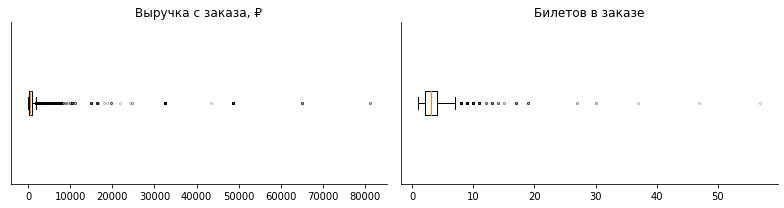

In [9]:
measures = ['revenue_rub', 'tickets_count']
display(orders[measures].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)
assert orders[['order_dt', 'order_ts', *measures]].notna().all().all()
assert orders['days_since_prev'].dropna().ge(0).all()
negative_revenue = int(orders['revenue_rub'].lt(0).sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, field, title in zip(axes, measures, ['Выручка с заказа, ₽', 'Билетов в заказе']):
    ax.boxplot(orders[field], vert=False, flierprops={'markersize': 2, 'alpha': .25})
    ax.set_title(title)
    ax.set_yticks([])
fig.tight_layout()
plt.show()

In [10]:
revenue_p99 = orders['revenue_rub'].quantile(.99)
large_revenue = orders['revenue_rub'].gt(revenue_p99)
invalid_tickets = orders['tickets_count'].lt(1)
clean_orders = orders.loc[~(large_revenue | invalid_tickets)].sort_values(
    ['user_id', 'order_ts', 'order_id']
).copy()
# После удаления заказов интервалы измеряются между оставшимися покупками.
clean_orders['days_since_prev'] = (
    clean_orders.groupby('user_id')['order_dt'].diff().dt.days.astype('Int16')
)
removed = len(orders) - len(clean_orders)
lost_users = orders['user_id'].nunique() - clean_orders['user_id'].nunique()
summary(
    f"Максимальная выручка {orders['revenue_rub'].max():,.2f} ₽ существенно выше "
    f"99-го перцентиля {revenue_p99:,.2f} ₽. Выше порога — {large_revenue.sum():,} заказов. "
    f"Заказов с числом билетов меньше одного — {invalid_tickets.sum():,}. "
    f"Всего исключено **{removed:,}** строк ({pct(removed / len(orders))}) "
    f"и потеряно {lost_users:,} пользователей. "
    f"Отрицательных значений выручки в исходной выборке — {negative_revenue:,}. "
    "Оставляю их в анализе денежного результата, поскольку причина отрицательных сумм в выгрузке не указана. "
    "Интервалы пересчитаны после фильтрации."
)

Максимальная выручка 81,174.54 ₽ существенно выше 99-го перцентиля 2,628.42 ₽. Выше порога — 2,825 заказов. Заказов с числом билетов меньше одного — 0. Всего исключено **2,825** строк (1.0%) и потеряно 79 пользователей. Отрицательных значений выручки в исходной выборке — 381. Оставляю их в анализе денежного результата, поскольку причина отрицательных сумм в выгрузке не указана. Интервалы пересчитаны после фильтрации.

 В проверенных категориальных полях пустых меток нет. Дату и время заказа преобразовали при чтении из базы. Для числа билетов уменьшили разрядность целого типа, а интервалы записали в целочисленный тип, который поддерживает пропуски.

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---


In [11]:
first_order = clean_orders.drop_duplicates('user_id').set_index('user_id')
profile = clean_orders.groupby('user_id').agg(
    first_order_dt=('order_dt', 'min'),
    last_order_dt=('order_dt', 'max'),
    total_orders=('order_id', 'size'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets_count=('tickets_count', 'mean'),
    avg_days_since_prev=('days_since_prev', 'mean'),
)
first_fields = {
    'device_type_canonical': 'first_device',
    'region_name': 'first_region',
    'service_name': 'first_service',
    'event_type_main': 'first_event_type',
}
profile = profile.join(first_order[list(first_fields)].rename(columns=first_fields))
profile['is_two'] = profile['total_orders'].ge(2)
profile['is_five'] = profile['total_orders'].ge(5)
profile['order_group'] = pd.cut(
    profile['total_orders'], [0, 1, 4, np.inf], labels=['1 заказ', '2–4 заказа', '5+ заказов']
)
profile['lifetime_days'] = (profile['last_order_dt'] - profile['first_order_dt']).dt.days
profile['observed_days'] = (observation_end - profile['first_order_dt']).dt.days
assert profile['avg_days_since_prev'].isna().eq(~profile['is_two']).all()
display(profile.head())

,first_order_dt,last_order_dt,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_since_prev,first_device,first_region,first_service,first_event_type,is_two,is_five,order_group,lifetime_days,observed_days
user_id,,,,,,,,,,,,,,,
0002849b70a3ce2,2024-08-20,2024-08-20,1,"1,521.94",4.00,<NA>,mobile,Каменевский регион,Край билетов,театр,False,False,1 заказ,0,72
0005ca5e93f2cf4,2024-07-23,2024-10-06,2,774.01,3.00,75.00,mobile,Каменевский регион,Мой билет,выставки,True,False,2–4 заказа,75,100
000898990054619,2024-07-13,2024-10-23,3,767.21,2.67,51.00,mobile,Североярская область,Лови билет!,другое,True,False,2–4 заказа,102,110
00096d1f542ab2b,2024-08-15,2024-08-15,1,917.83,4.00,<NA>,desktop,Каменевский регион,Край билетов,театр,False,False,1 заказ,0,77
000a55a418c128c,2024-09-29,2024-10-15,2,61.31,1.50,16.00,mobile,Поленовский край,Лучшие билеты,театр,True,False,2–4 заказа,16,32


---

**Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

In [12]:
repeat_rate = profile['is_two'].mean()
five_rate = profile['is_five'].mean()
mean_order_revenue = np.average(profile['avg_revenue_rub'], weights=profile['total_orders'])
display(pd.Series({
    'Пользователей': len(profile),
    'Средняя выручка с заказа, ₽': mean_order_revenue,
    'Пользователей с 2+ заказами, %': 100 * repeat_rate,
    'Пользователей с 5+ заказами, %': 100 * five_rate,
}).to_frame('Значение'))
display(profile['order_group'].value_counts(sort=False).rename('Пользователи').to_frame())
profile_numeric = ['total_orders', 'avg_tickets_count', 'avg_days_since_prev']
display(profile[profile_numeric].describe(percentiles=[.25, .5, .75, .95, .99]).T)

,Значение
Пользователей,"21,854.00"
"Средняя выручка с заказа, ₽",518.03
"Пользователей с 2+ заказами, %",61.71
"Пользователей с 5+ заказами, %",29.01


,Пользователи
1 заказ,8368
2–4 заказа,7147
5+ заказов,6339


,count,mean,std,min,25%,50%,75%,95%,99%,max
total_orders,"21,854.00",13.17,121.67,1.00,1.00,2.00,5.00,31.35,152.00,"10,181.00"
avg_tickets_count,"21,854.00",2.74,0.91,1.00,2.00,2.75,3.08,4.00,5.00,11.00
avg_days_since_prev,"13,486.00",15.88,22.27,0.00,1.00,8.07,20.50,61.50,112.00,148.00


In [13]:
order_p99 = profile['total_orders'].quantile(.99)
ticket_p99 = profile['avg_tickets_count'].quantile(.99)
summary(
    f"Профиль рассчитан для **{len(profile):,} пользователей**. "
    f"Повторный заказ сделали {pct(repeat_rate)}, пять и более — {pct(five_rate)}. "
    f"99-й перцентиль числа заказов равен {order_p99:.0f}, максимум — {profile['total_orders'].max():,}. "
    f"Для среднего числа билетов 99-й перцентиль равен {ticket_p99:.2f}, "
    f"максимум — {profile['avg_tickets_count'].max():.2f}. "
    "Профили с большими значениями сохраняю, поскольку фильтр по числу заказов исказил бы целевую метрику. "
    "Для типичных значений использую медианы. В небольших сегментах доли чувствительны к каждой покупке."
)

Профиль рассчитан для **21,854 пользователей**. Повторный заказ сделали 61.7%, пять и более — 29.0%. 99-й перцентиль числа заказов равен 152, максимум — 10,181. Для среднего числа билетов 99-й перцентиль равен 5.00, максимум — 11.00. Профили с большими значениями сохраняю, поскольку фильтр по числу заказов исказил бы целевую метрику. Для типичных значений использую медианы. В небольших сегментах доли чувствительны к каждой покупке.

21 854 пользователей достаточно для описательного сравнения крупных сегментов в этом срезе. Результаты относятся к заказам с мобильных устройств и компьютеров за июнь–октябрь 2024 года, из которых исключены фильмы. У небольшой части пользователей число заказов намного выше типичного: медиана составляет 2, а максимум — 10 181. Эти значения сохранены при подсчёте возврата, но столь активные профили стоит проверить отдельно перед обучением модели.

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---


In [14]:
segment_fields = {
    'first_event_type': 'Тип первого мероприятия',
    'first_device': 'Устройство первого заказа',
    'first_region': 'Регион первого заказа',
    'first_service': 'Оператор первого заказа',
}

def segment_stats(field):
    result = profile.groupby(field, observed=True).agg(
        users=('is_two', 'size'),
        returned=('is_two', 'sum'),
        repeat_rate=('is_two', 'mean'),
    )
    return result.assign(user_share=result['users'] / len(profile)).sort_values(
        'users', ascending=False
    )

segments = {field: segment_stats(field) for field in segment_fields}
for field, title in segment_fields.items():
    table = segments[field]
    summary(f"**{title}.** Сегмент «{table.index[0]}» охватывает {pct(table.iloc[0]['user_share'])} пользователей.")
    display(table[['users', 'user_share']].style.format({'user_share': '{:.1%}'}))

**Тип первого мероприятия.** Сегмент «концерты» охватывает 44.1% пользователей.

,users,user_share
first_event_type,,
концерты,9643,44.1%
другое,5490,25.1%
театр,4289,19.6%
стендап,1118,5.1%
спорт,801,3.7%
выставки,418,1.9%
ёлки,95,0.4%


**Устройство первого заказа.** Сегмент «mobile» охватывает 82.9% пользователей.

,users,user_share
first_device,,
mobile,18108,82.9%
desktop,3746,17.1%


**Регион первого заказа.** Сегмент «Каменевский регион» охватывает 32.8% пользователей.

,users,user_share
first_region,,
Каменевский регион,7159,32.8%
Североярская область,3799,17.4%
Широковская область,1237,5.7%
Озернинский край,678,3.1%
Малиновоярский округ,529,2.4%
Шанырский регион,503,2.3%
Травяная область,493,2.3%
Светополянский округ,464,2.1%
Речиновская область,446,2.0%


**Оператор первого заказа.** Сегмент «Билеты без проблем» охватывает 23.9% пользователей.

,users,user_share
first_service,,
Билеты без проблем,5223,23.9%
Мой билет,2992,13.7%
Лови билет!,2848,13.0%
Билеты в руки,2594,11.9%
Облачко,2194,10.0%
Весь в билетах,1304,6.0%
Лучшие билеты,1188,5.4%
Прачечная,588,2.7%
Край билетов,459,2.1%


---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---


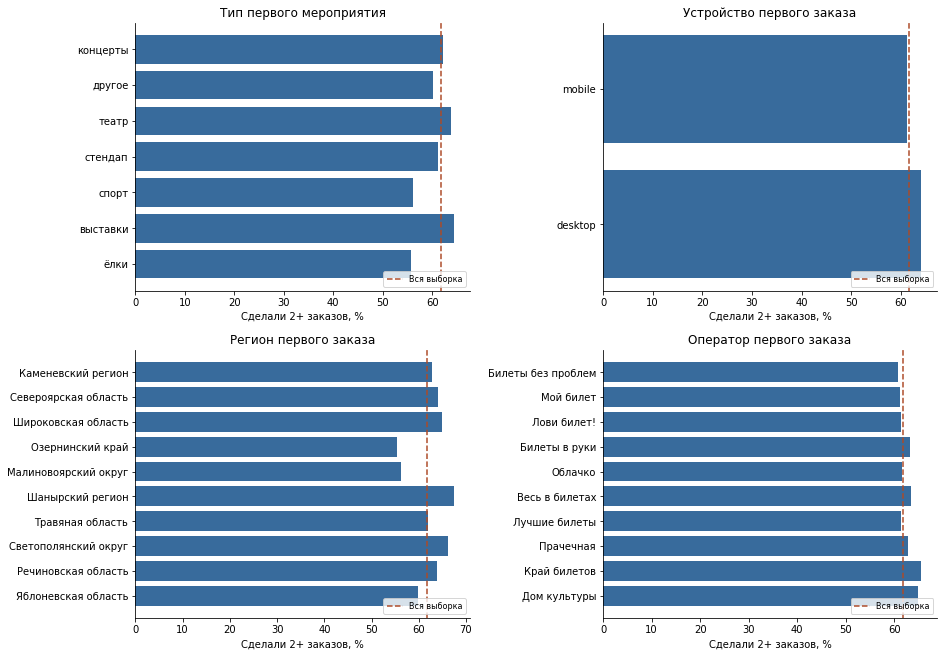

In [15]:
def plot_repeat(table, title, ax):
    values = table.iloc[::-1]
    ax.barh(values.index.astype(str), values['repeat_rate'] * 100, color='#386b9c')
    ax.axvline(100 * repeat_rate, color='#ad4a28', linestyle='--', label='Вся выборка')
    ax.set(xlabel='Сделали 2+ заказов, %', title=title)
    ax.legend(loc='lower right', fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for ax, (field, title) in zip(axes.flat, segment_fields.items()):
    plot_repeat(segments[field].head(10), title, ax)
plt.show()

In [16]:
# Для текстового сравнения берём сегменты с хотя бы 100 пользователями.
min_segment_size = 100
for field, title in segment_fields.items():
    table = segments[field]
    large = table.loc[table['users'].ge(min_segment_size)].sort_values('repeat_rate', ascending=False)
    leader = large.iloc[0]
    above = large.loc[large['repeat_rate'].gt(repeat_rate)].head(3)
    labels = ', '.join(str(label) for label in above.index) or 'сегментов выше среднего нет'
    summary(
        f"**{title}.** Лидер среди сегментов от {min_segment_size} пользователей — «{large.index[0]}» "
        f"({pct(leader['repeat_rate'])}, n={int(leader['users']):,}). Сегменты выше общей доли — {labels}."
    )
    display(table[['users', 'returned', 'repeat_rate']].style.format({'repeat_rate': '{:.1%}'}))

**Тип первого мероприятия.** Лидер среди сегментов от 100 пользователей — «выставки» (64.4%, n=418). Сегменты выше общей доли — выставки, театр, концерты.

,users,returned,repeat_rate
first_event_type,,,
концерты,9643,5994,62.2%
другое,5490,3299,60.1%
театр,4289,2737,63.8%
стендап,1118,684,61.2%
спорт,801,450,56.2%
выставки,418,269,64.4%
ёлки,95,53,55.8%


**Устройство первого заказа.** Лидер среди сегментов от 100 пользователей — «desktop» (64.1%, n=3,746). Сегменты выше общей доли — desktop.

,users,returned,repeat_rate
first_device,,,
mobile,18108,11084,61.2%
desktop,3746,2402,64.1%


**Регион первого заказа.** Лидер среди сегментов от 100 пользователей — «Горицветская область» (67.8%, n=255). Сегменты выше общей доли — Горицветская область, Шанырский регион, Берёзовская область.

,users,returned,repeat_rate
first_region,,,
Каменевский регион,7159,4495,62.8%
Североярская область,3799,2436,64.1%
Широковская область,1237,803,64.9%
Озернинский край,678,376,55.5%
Малиновоярский округ,529,298,56.3%
Шанырский регион,503,339,67.4%
Травяная область,493,305,61.9%
Светополянский округ,464,307,66.2%
Речиновская область,446,285,63.9%


**Оператор первого заказа.** Лидер среди сегментов от 100 пользователей — «Show_ticket» (66.3%, n=163). Сегменты выше общей доли — Show_ticket, Край билетов, Мир касс.

,users,returned,repeat_rate
first_service,,,
Билеты без проблем,5223,3170,60.7%
Мой билет,2992,1830,61.2%
Лови билет!,2848,1750,61.4%
Билеты в руки,2594,1640,63.2%
Облачко,2194,1351,61.6%
Весь в билетах,1304,827,63.4%
Лучшие билеты,1188,729,61.4%
Прачечная,588,370,62.9%
Край билетов,459,301,65.6%


---

**Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

In [17]:
# Односторонний тест двух долей с общей оценкой доли под H0.
def compare_rates(a, b):
    rate_a, rate_b = a.mean(), b.mean()
    pooled = (a.sum() + b.sum()) / (len(a) + len(b))
    error = np.sqrt(pooled * (1 - pooled) * (1 / len(a) + 1 / len(b)))
    return {
        'n_a': len(a), 'n_b': len(b), 'rate_a': rate_a, 'rate_b': rate_b,
        'difference_pp': 100 * (rate_a - rate_b), 'p_one_sided': norm.sf((rate_a - rate_b) / error)
    }

top_regions = segments['first_region'].head(10).index
sport = profile['first_event_type'].eq('спорт')
concert = profile['first_event_type'].eq('концерты')
top_region_mask = profile['first_region'].isin(top_regions)
hypotheses = {
    'Спорт / концерты': (sport, concert),
    'Топ-10 регионов / остальные': (top_region_mask, ~top_region_mask),
}
hypothesis_results = pd.DataFrame({
    label: compare_rates(profile.loc[a, 'is_two'], profile.loc[b, 'is_two'])
    for label, (a, b) in hypotheses.items()
}).T
display(hypothesis_results.style.format({
    'n_a': '{:,.0f}', 'n_b': '{:,.0f}', 'rate_a': '{:.1%}', 'rate_b': '{:.1%}',
    'difference_pp': '{:+.2f}', 'p_one_sided': '{:.3g}',
}))

,n_a,n_b,rate_a,rate_b,difference_pp,p_one_sided
Спорт / концерты,801,"9,643",56.2%,62.2%,-5.98,1
Топ-10 регионов / остальные,"15,724","6,130",62.9%,58.6%,+4.30,2.06e-09


In [18]:
# Сравниваем те же группы на одинаковом окне в 30 дней.
eligible = profile['observed_days'].ge(30)
second_order = clean_orders.loc[
    clean_orders.groupby('user_id').cumcount().eq(1), ['user_id', 'order_dt']
].set_index('user_id')['order_dt']
repeat_30d = second_order.reindex(profile.index).sub(profile['first_order_dt']).dt.days.le(30)
results_30d = pd.DataFrame({
    label: compare_rates(repeat_30d.loc[eligible & a], repeat_30d.loc[eligible & b])
    for label, (a, b) in hypotheses.items()
}).T
display(results_30d[['rate_a', 'rate_b', 'difference_pp', 'p_one_sided']].style.format({
    'rate_a': '{:.1%}', 'rate_b': '{:.1%}', 'difference_pp': '{:+.2f}', 'p_one_sided': '{:.3g}',
}))
for label, row in hypothesis_results.iterrows():
    verdict = 'поддержана данными' if row['p_one_sided'] < .05 else 'не получила поддержки'
    summary(
        f"**{label}.** Гипотеза {verdict} при уровне 5% "
        f"({row['difference_pp']:+.2f} п. п., p={row['p_one_sided']:.3g}). "
        f"Для одинакового окна в 30 дней разница {results_30d.loc[label, 'difference_pp']:+.2f} п. п."
    )
summary("Топ-10 регионов определён по размеру сегмента первого заказа. Различия наблюдательные.")

,rate_a,rate_b,difference_pp,p_one_sided
Спорт / концерты,52.9%,48.9%,+3.98,0.0316
Топ-10 регионов / остальные,49.3%,50.5%,-1.15,0.912


**Спорт / концерты.** Гипотеза не получила поддержки при уровне 5% (-5.98 п. п., p=1). Для одинакового окна в 30 дней разница +3.98 п. п.

**Топ-10 регионов / остальные.** Гипотеза поддержана данными при уровне 5% (+4.30 п. п., p=2.06e-09). Для одинакового окна в 30 дней разница -1.15 п. п.

Топ-10 регионов определён по размеру сегмента первого заказа. Различия наблюдательные.

Что меняется при одинаковом сроке наблюдения: за 30 дней повторный заказ сделали 52,9% пользователей, начавших со спорта, и 48,9% начавших с концертов (односторонний p = 0,032). Для топ-10 регионов доля составила 49,3%, для остальных — 50,5% (p = 0,912 для гипотезы о преимуществе топ-10). Направления обеих разниц меняются относительно сравнения за весь период. Для оценки кампаний лучше заранее зафиксировать единый горизонт возвратаОдин заказ и повторные покупки. Самый частый интервал средней выручки на пользователя — от −11 до 55 ₽ у покупателей с одним заказом и от 451 до 517 ₽ у вернувшихся. Медиана у вернувшихся выше (497,62 против 378,03 ₽), при этом средние по группам близки (543,84 и 545,30 ₽).Один заказ и повторные покупки. Самый частый интервал средней выручки на пользователя — от −11 до 55 ₽ у покупателей с одним заказом и от 451 до 517 ₽ у вернувшихся. Медиана у вернувшихся выше (497,62 против 378,03 ₽), при этом средние по группам близки (543,84 и 545,30 ₽).Один заказ и повторные покупки. Самый частый интервал средней выручки на пользователя — от −11 до 55 ₽ у покупателей с одним заказом и от 451 до 517 ₽ у вернувшихся. Медиана у вернувшихся выше (497,62 против 378,03 ₽), при этом средние по группам близки (543,84 и 545,30 ₽).

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

Текст на сером фоне:
    
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

---


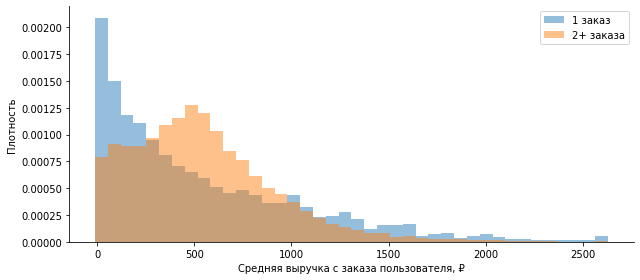

,Пользователи,"Среднее, ₽","Медиана, ₽","25-й перцентиль, ₽","75-й перцентиль, ₽","Пиковый интервал, ₽"
1 заказ,8368,545.30,378.03,132.07,830.32,-11–55
2+ заказа,13486,543.84,497.62,274.11,739.35,451–517


Разница медиан второй и первой групп — **+119.59 ₽**. Пиковые интервалы показывают, где выше всего концентрация пользователей.

In [19]:
def compare_revenue(groups):
    data = {label: profile.loc[mask, 'avg_revenue_rub'] for label, mask in groups.items()}
    bins = np.histogram_bin_edges(pd.concat(data.values()), bins=40)
    fig, ax = plt.subplots(figsize=(9, 4))
    for label, values in data.items():
        ax.hist(values, bins=bins, alpha=.48, density=True, label=label)
    ax.set(xlabel='Средняя выручка с заказа пользователя, ₽', ylabel='Плотность')
    ax.legend()
    fig.tight_layout()
    plt.show()
    rows = {}
    for label, values in data.items():
        count, _ = np.histogram(values, bins=bins)
        mode = int(count.argmax())
        rows[label] = {
            'Пользователи': len(values), 'Среднее, ₽': values.mean(), 'Медиана, ₽': values.median(),
            '25-й перцентиль, ₽': values.quantile(.25), '75-й перцентиль, ₽': values.quantile(.75),
            'Пиковый интервал, ₽': f'{bins[mode]:.0f}–{bins[mode + 1]:.0f}',
        }
    stats = pd.DataFrame(rows).T
    difference = stats.iloc[1]['Медиана, ₽'] - stats.iloc[0]['Медиана, ₽']
    display(stats)
    summary(f"Разница медиан второй и первой групп — **{difference:+.2f} ₽**. "
            "Пиковые интервалы показывают, где выше всего концентрация пользователей.")
    return stats

revenue_repeat = compare_revenue({'1 заказ': ~profile['is_two'], '2+ заказа': profile['is_two']})

 Самый частый интервал средней выручки на пользователя — от −11 до 55 ₽ у покупателей с одним заказом и от 451 до 517 ₽ у вернувшихся. Медиана у вернувшихся выше (497,62 против 378,03 ₽), при этом средние по группам близки (543,84 и 545,30 ₽).

---

**Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

---


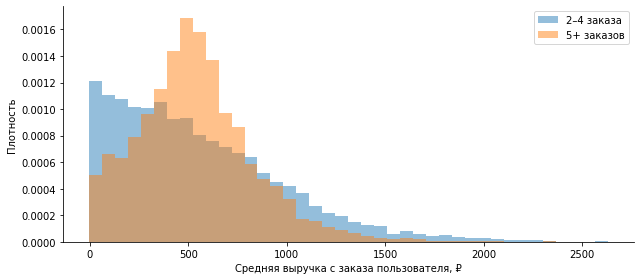

,Пользователи,"Среднее, ₽","Медиана, ₽","25-й перцентиль, ₽","75-й перцентиль, ₽","Пиковый интервал, ₽"
2–4 заказа,7147,551.57,471.27,218.43,798.55,-5–60
5+ заказов,6339,535.12,513.56,336.97,690.02,456–521


Разница медиан второй и первой групп — **+42.29 ₽**. Пиковые интервалы показывают, где выше всего концентрация пользователей.

Средняя выручка пользователя рассчитана по всем наблюдаемым заказам. Это характеристика поведения в периоде исследования.

In [20]:
revenue_frequency = compare_revenue({
    '2–4 заказа': profile['is_two'] & ~profile['is_five'],
    '5+ заказов': profile['is_five'],
})
summary("Средняя выручка пользователя рассчитана по всем наблюдаемым заказам. "
        "Это характеристика поведения в периоде исследования.")

От 2 до 4 заказов и 5+ заказов. У более активной группы медиана выше (513,56 против 471,27 ₽), хотя среднее ниже (535,12 против 551,57 ₽). Вывод о различии зависит от того, какой показатель сравнивается

---

**Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

---

,users,returned,repeat_rate,user_share
ticket_segment,,,,
[1; 2),2419,1241,51.3%,11.1%
[2; 3),9706,7197,74.2%,44.4%
[3; 5),9068,4924,54.3%,41.5%
5 и более,661,124,18.8%,3.0%


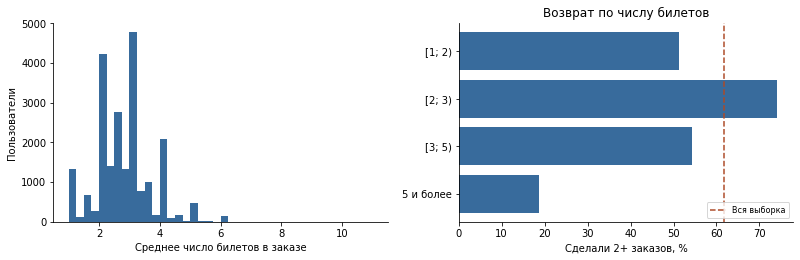

In [21]:
ticket_labels = ['[1; 2)', '[2; 3)', '[3; 5)', '5 и более']
profile['ticket_segment'] = pd.cut(
    profile['avg_tickets_count'], [1, 2, 3, 5, np.inf], labels=ticket_labels, right=False
)
assert profile['ticket_segment'].notna().all()
ticket_segments = segment_stats('ticket_segment').reindex(ticket_labels)
display(ticket_segments.style.format({'repeat_rate': '{:.1%}', 'user_share': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].hist(profile['avg_tickets_count'], bins=40, color='#386b9c')
axes[0].set(xlabel='Среднее число билетов в заказе', ylabel='Пользователи')
plot_repeat(ticket_segments, 'Возврат по числу билетов', axes[1])
plt.show()

In [22]:
top_ticket_segment = ticket_segments['users'].idxmax()
high_ticket_rate = ticket_segments['repeat_rate'].idxmax()
low_ticket_rate = ticket_segments['repeat_rate'].idxmin()
summary(
    f"Наибольший сегмент — **{top_ticket_segment}** билета "
    f"({pct(ticket_segments.loc[top_ticket_segment, 'user_share'])} пользователей). "
    f"Медиана среднего числа билетов — {profile['avg_tickets_count'].median():.2f}. "
    f"Выше всего доля возврата в сегменте «{high_ticket_rate}» "
    f"({pct(ticket_segments.loc[high_ticket_rate, 'repeat_rate'])}), ниже всего — «{low_ticket_rate}» "
    f"({pct(ticket_segments.loc[low_ticket_rate, 'repeat_rate'])}). "
    "Таблица показывает размер каждого сегмента для оценки устойчивости крайних долей."
)

Наибольший сегмент — **[2; 3)** билета (44.4% пользователей). Медиана среднего числа билетов — 2.75. Выше всего доля возврата в сегменте «[2; 3)» (74.2%), ниже всего — «5 и более» (18.8%). Таблица показывает размер каждого сегмента для оценки устойчивости крайних долей.

 85,9% пользователей в среднем покупают от 2 до менее чем 5 билетов. Среди покупателей со средним от 2 до менее чем 3 билетов возвращаются 74,2% из 9 706 пользователей. В группе со средним от 5 билетов возвращаются 18,8% из 661 пользователя. Среднее число билетов рассчитано по всем заказам пользователя, поэтому эти доли описывают связь в выборке.

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---


,users,returned,repeat_rate,user_share,repeat_30d
first_weekday,,,,,
Пн,2943,1860,63.2%,13.5%,50.5%
Вт,3189,1979,62.1%,14.6%,49.9%
Ср,3072,1916,62.4%,14.1%,51.8%
Чт,3120,1857,59.5%,14.3%,46.4%
Пт,3261,1952,59.9%,14.9%,47.3%
Сб,3459,2222,64.2%,15.8%,52.0%
Вс,2810,1700,60.5%,12.9%,49.0%


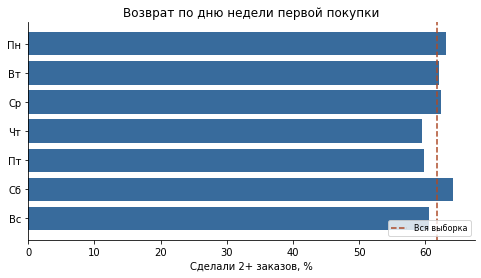

Наибольшая наблюдаемая доля — Сб, наименьшая — Чт. Разброс — 4.72 п. п. В одинаковом окне в 30 дней разброс составляет 5.62 п. п.

In [23]:
weekdays = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
profile['first_weekday'] = pd.Categorical.from_codes(
    profile['first_order_dt'].dt.dayofweek, categories=weekdays, ordered=True
)
weekday_stats = segment_stats('first_weekday').reindex(weekdays)
weekday_stats['repeat_30d'] = repeat_30d.loc[eligible].groupby(
    profile.loc[eligible, 'first_weekday'], observed=True
).mean()
display(weekday_stats.style.format({
    'repeat_rate': '{:.1%}', 'repeat_30d': '{:.1%}', 'user_share': '{:.1%}',
}))
fig, ax = plt.subplots(figsize=(8, 4))
plot_repeat(weekday_stats, 'Возврат по дню недели первой покупки', ax)
plt.show()
weekday_spread = 100 * (weekday_stats['repeat_rate'].max() - weekday_stats['repeat_rate'].min())
weekday_30d_spread = 100 * (weekday_stats['repeat_30d'].max() - weekday_stats['repeat_30d'].min())
summary(
    f"Наибольшая наблюдаемая доля — {weekday_stats['repeat_rate'].idxmax()}, "
    f"наименьшая — {weekday_stats['repeat_rate'].idxmin()}. Разброс — {weekday_spread:.2f} п. п. "
    f"В одинаковом окне в 30 дней разброс составляет {weekday_30d_spread:.2f} п. п."
)

В выборке возврат после первой покупки в субботу наблюдается чаще, чем после покупки в четверг. За одинаковые 30 дней доли составляют 52,0% и 46,4% соответственно. Это наблюдаемая связь, которую стоит перепроверить на другой когорте, прежде чем планировать кампанию по дням недели.

---

**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

---


In [24]:
interval_stats = profile.loc[profile['is_two']].groupby('order_group', observed=True).agg(
    users=('total_orders', 'size'),
    mean_interval=('avg_days_since_prev', 'mean'),
    median_interval=('avg_days_since_prev', 'median'),
    median_lifetime=('lifetime_days', 'median'),
    median_observation=('observed_days', 'median'),
)
display(interval_stats)
interval_difference = interval_stats.iloc[1]['mean_interval'] - interval_stats.iloc[0]['mean_interval']
summary(
    f"Для группы с 5+ заказами средний интервал отличается на {interval_difference:+.2f} дня "
    "от группы с 2–4 заказами. Интервалы доступны только у вернувшихся пользователей. "
    "Сравнение описывает частоту покупок этих групп. Короткое окно наблюдения ограничивает число заказов."
)

,users,mean_interval,median_interval,median_lifetime,median_observation
order_group,,,,,
2–4 заказа,7147,21.41,9.00,15,76
5+ заказов,6339,9.64,7.83,111,130


Для группы с 5+ заказами средний интервал отличается на -11.76 дня от группы с 2–4 заказами. Интервалы доступны только у вернувшихся пользователей. Сравнение описывает частоту покупок этих групп. Короткое окно наблюдения ограничивает число заказов.

У группы с 5+ заказами средний интервал составляет 9,64 дня против 21,41 дня у группы с 2–4 заказами. Медиана времени между первым и последним заказом составляет 111 и 15 дней соответственно. Интервал появляется только после повторной покупки, поэтому он подходит для описания активности уже вернувшихся клиентов.

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

---

In [25]:
try:
    import phik
except ModuleNotFoundError as exc:
    if exc.name != 'phik':
        raise
    import importlib
    import subprocess
    import sys

    import scipy
    from packaging.version import Version

    package = 'phik==0.12.3' if Version(scipy.__version__) < Version('1.8') else 'phik'
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
    importlib.invalidate_caches()
    import phik

# Не включаем признаки, вычисленные напрямую из числа заказов.
phik_features = list(segment_fields) + [
    'first_weekday', 'observed_days', 'avg_revenue_rub', 'avg_tickets_count'
]
interval_columns = ['observed_days', 'avg_revenue_rub', 'avg_tickets_count']
# Сохраняем все признаки, объединяя лишь редкие уровни региона и оператора.
phik_input = profile[phik_features + ['total_orders', 'order_group']].copy()
for field in ['first_region', 'first_service']:
    frequencies = phik_input[field].value_counts()
    frequent = frequencies[frequencies.ge(50)].index
    phik_input[field] = phik_input[field].astype('object').where(
        phik_input[field].isin(frequent), 'Редкие категории'
    )

phi_scores = pd.DataFrame(index=phik_features)
for target, label in [('total_orders', 'Число заказов'), ('order_group', 'Группа заказов')]:
    values = {}
    for field in phik_features:
        intervals = [column for column in [field, target]
                     if column in interval_columns + ['total_orders']]
        matrix = phik_input[[field, target]].phik_matrix(interval_cols=intervals, njobs=1)
        values[field] = matrix.loc[field, target]
    phi_scores[label] = pd.Series(values)
phi_scores = phi_scores.sort_values('Группа заказов', ascending=False)
display(phi_scores)

,Число заказов,Группа заказов
observed_days,0.05,0.48
avg_tickets_count,0.00,0.39
avg_revenue_rub,0.00,0.33
first_region,0.07,0.12
first_service,0.03,0.07
first_weekday,0.06,0.05
first_event_type,0.00,0.04
first_device,0.00,0.02


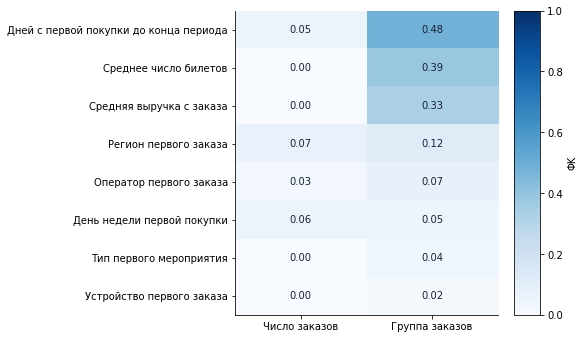

**Число заказов.** Наибольшие значения ΦK — Регион первого заказа (0.07), День недели первой покупки (0.06), Дней с первой покупки до конца периода (0.05).

**Группа заказов.** Наибольшие значения ΦK — Дней с первой покупки до конца периода (0.48), Среднее число билетов (0.39), Средняя выручка с заказа (0.33).

ΦK показывает силу связи. Средние по всем заказам доступны после покупок, поэтому для прогноза сразу после первой покупки потребуются признаки первого заказа.

In [26]:
feature_labels = {
    **segment_fields, 'first_weekday': 'День недели первой покупки',
    'observed_days': 'Дней с первой покупки до конца периода',
    'avg_revenue_rub': 'Средняя выручка с заказа',
    'avg_tickets_count': 'Среднее число билетов',
}
fig, ax = plt.subplots(figsize=(8, 4.6), constrained_layout=True)
heat = ax.imshow(phi_scores, aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(phi_scores.columns)))
ax.set_xticklabels(phi_scores.columns)
ax.set_yticks(range(len(phi_scores)))
ax.set_yticklabels([feature_labels[field] for field in phi_scores.index])
for row, scores in enumerate(phi_scores.to_numpy()):
    for col, score in enumerate(scores):
        ax.text(col, row, f'{score:.2f}', ha='center', va='center',
                color='white' if score > .55 else '#172235')
fig.colorbar(heat, ax=ax, label='ΦK')
plt.show()
for target in phi_scores:
    scores = phi_scores[target].nlargest(3)
    description = ', '.join(f'{feature_labels[field]} ({value:.2f})' for field, value in scores.items())
    summary(f"**{target}.** Наибольшие значения ΦK — {description}.")
summary("ΦK показывает силу связи. Средние по всем заказам доступны после покупок, "
        "поэтому для прогноза сразу после первой покупки потребуются признаки первого заказа.")

В исходном числе заказов есть длинный правый хвост. После деления пользователей на группы сильнее всего с числом покупок связана длина наблюдения (ΦK = 0,48), а среди признаков первого заказа наибольшее значение у региона (0,12). Это слабая связь для признака первого заказа

### 5. Общий вывод и рекомендации

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

In [27]:
early_features = [*segment_fields, 'first_weekday']
top_early_feature = phi_scores.loc[early_features, 'Группа заказов'].idxmax()
event_repeat = segments['first_event_type'].loc[['спорт', 'концерты'], 'repeat_rate']
region_h2 = hypothesis_results.loc['Топ-10 регионов / остальные']
revenue_once = revenue_repeat.loc['1 заказ', 'Медиана, ₽']
revenue_repeaters = revenue_repeat.loc['2+ заказа', 'Медиана, ₽']
summary(f"""
**Данные и подготовка.** Выгрузка охватывает {raw['order_dt'].min():%d.%m.%Y}–{observation_end:%d.%m.%Y}.
В анализе {len(clean_orders):,} заказов и {len(profile):,} пользователей.
Оставлены устройства mobile и desktop, исключены фильмы, {kzt.sum():,} заказов пересчитаны по дневному курсу.
При предобработке исключено {removed:,} заказов ({pct(removed / len(orders))}).

**Повторные покупки.** {pct(repeat_rate)} пользователей сделали 2+ заказа, {pct(five_rate)} — 5+.
Средняя выручка на заказ составила {mean_order_revenue:,.2f} ₽.
После первого заказа на спорт вернулись {pct(event_repeat['спорт'])}, после концертов — {pct(event_repeat['концерты'])}.
Для топ-10 регионов показатель составил {pct(region_h2['rate_a'])}, для остальных — {pct(region_h2['rate_b'])}.

**Выручка и билеты.** Медиана средней выручки по пользователям с одним заказом — {revenue_once:.2f} ₽,
с повторным — {revenue_repeaters:.2f} ₽. Самый массовый сегмент по среднему числу билетов —
{top_ticket_segment} ({pct(ticket_segments.loc[top_ticket_segment, 'user_share'])}).
Доли возврата по сегментам лежат в пределах {pct(ticket_segments['repeat_rate'].min())}–{pct(ticket_segments['repeat_rate'].max())}.

**Время и связь признаков.** Разброс долей по дням недели — {weekday_spread:.2f} п. п.,
на одинаковом горизонте 30 дней — {weekday_30d_spread:.2f} п. п.
У пользователей с 5+ заказами средний интервал отличается от группы с 2–4 заказами на {interval_difference:+.2f} дня.
Среди признаков первого заказа наиболее высокий ΦK с группой заказов у показателя
«{feature_labels[top_early_feature]}» ({phi_scores.loc[top_early_feature, 'Группа заказов']:.2f}).
""")


**Данные и подготовка.** Выгрузка охватывает 01.06.2024–31.10.2024.
В анализе 287,786 заказов и 21,854 пользователей.
Оставлены устройства mobile и desktop, исключены фильмы, 5,069 заказов пересчитаны по дневному курсу.
При предобработке исключено 2,825 заказов (1.0%).

**Повторные покупки.** 61.7% пользователей сделали 2+ заказа, 29.0% — 5+.
Средняя выручка на заказ составила 518.03 ₽.
После первого заказа на спорт вернулись 56.2%, после концертов — 62.2%.
Для топ-10 регионов показатель составил 62.9%, для остальных — 58.6%.

**Выручка и билеты.** Медиана средней выручки по пользователям с одним заказом — 378.03 ₽,
с повторным — 497.62 ₽. Самый массовый сегмент по среднему числу билетов —
[2; 3) (44.4%).
Доли возврата по сегментам лежат в пределах 18.8%–74.2%.

**Время и связь признаков.** Разброс долей по дням недели — 4.72 п. п.,
на одинаковом горизонте 30 дней — 5.62 п. п.
У пользователей с 5+ заказами средний интервал отличается от группы с 2–4 заказами на -11.76 дня.
Среди признаков первого заказа наиболее высокий ΦK с группой заказов у показателя
«Регион первого заказа» (0.12).


In [28]:
concert_volume = int(segments['first_event_type'].loc['концерты', 'users'])
sport_volume = int(segments['first_event_type'].loc['спорт', 'users'])
concerts_30 = results_30d.loc['Спорт / концерты', 'rate_b']
sport_30 = results_30d.loc['Спорт / концерты', 'rate_a']
summary(f"""
**Рекомендации маркетингу**

1. Взять концерты как одну из стартовых аудиторий для теста рекомендаций после первой покупки
   ({concert_volume:,} пользователей). Спортивную аудиторию выделить отдельно ({sport_volume:,} пользователей).
   На горизонте 30 дней наблюдаемая доля возврата составила {pct(sport_30)} у спорта
   и {pct(concerts_30)} у концертов.
2. Для региональных кампаний отбирать сегменты по размеру и наблюдаемой доле возврата совместно.
   Оценивать результат по второму заказу за 30 дней с контрольной группой.
3. Для будущей модели фиксировать признаки на дату первого заказа и сравнивать когорты
   с одинаковым сроком наблюдения. Средний интервал между уже сделанными заказами можно
   использовать для отдельной задачи повторного вовлечения клиентов с несколькими покупками.
""")


**Рекомендации маркетингу**

1. Взять концерты как одну из стартовых аудиторий для теста рекомендаций после первой покупки
   (9,643 пользователей). Спортивную аудиторию выделить отдельно (801 пользователей).
   На горизонте 30 дней наблюдаемая доля возврата составила 52.9% у спорта
   и 48.9% у концертов.
2. Для региональных кампаний отбирать сегменты по размеру и наблюдаемой доле возврата совместно.
   Оценивать результат по второму заказу за 30 дней с контрольной группой.
3. Для будущей модели фиксировать признаки на дату первого заказа и сравнивать когорты
   с одинаковым сроком наблюдения. Средний интервал между уже сделанными заказами можно
   использовать для отдельной задачи повторного вовлечения клиентов с несколькими покупками.


### 6. Финализация проекта и публикация в Git

Когда вы закончите анализировать данные, оформите проект, а затем опубликуйте его.

Выполните следующие действия:

1. Создайте файл `.gitignore`. Добавьте в него все временные и чувствительные файлы, которые не должны попасть в репозиторий.
2. Сформируйте файл `requirements.txt`. Зафиксируйте все библиотеки, которые вы использовали в проекте.
3. Вынести все чувствительные данные (параметры подключения к базе) в `.env`файл.
4. Проверьте, что проект запускается и воспроизводим.
5. Загрузите проект в публичный репозиторий — например, на GitHub. Убедитесь, что все нужные файлы находятся в репозитории, исключая те, что в `.gitignore`. Ссылка на репозиторий понадобится для отправки проекта на проверку. Вставьте её в шаблон проекта в тетрадке Jupyter Notebook перед отправкой проекта на ревью.

https://github.com/lishk6/yandex-afisha-loyalty